In [100]:
import numpy as np
import pandas as pd

import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier



In [101]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [102]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [103]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [104]:
df['Age'] = df['Age'].fillna(df['Age'].mean(), inplace=True)

C:\Users\MY PC\AppData\Local\Temp\ipykernel_9012\1728128861.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Age'] = df['Age'].fillna(df['Age'].mean(), inplace=True)


In [105]:
df.isnull().sum()

Survived    0
Age         0
Fare        0
dtype: int64

In [106]:
x = df.iloc[:, 1:3]
y = df.iloc[:, 0]

In [107]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state= 42)

In [108]:
x_train

,Age,Fare
331,45.500000,28.5000
733,23.000000,13.0000
382,32.000000,7.9250
704,26.000000,7.8542
813,6.000000,31.2750
...,...,...
106,21.000000,7.6500
270,29.699118,31.0000
860,41.000000,14.1083
435,14.000000,120.0000


C:\Users\MY PC\AppData\Local\Temp\ipykernel_9012\1341541768.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Age'])


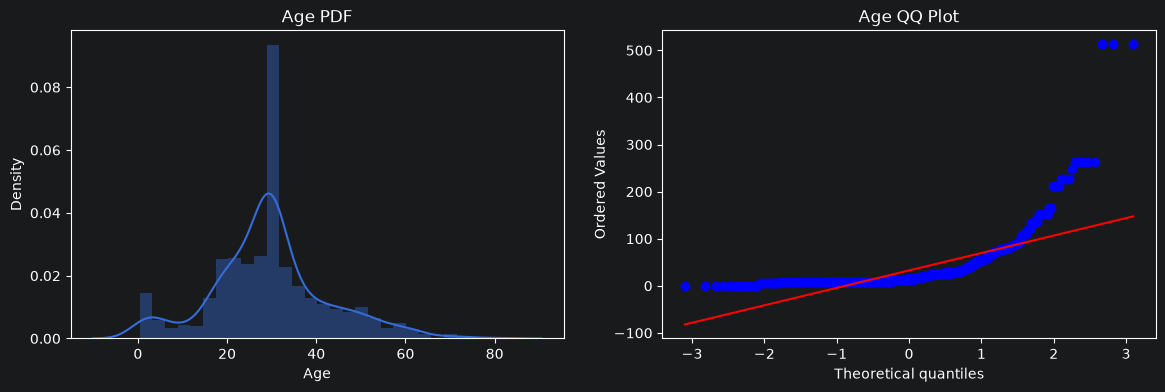

In [109]:
#distribution of input feature - Age
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(x_train['Age'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(x_train['Fare'], dist='norm', plot=plt)
plt.title('Age QQ Plot')

plt.show()

C:\Users\MY PC\AppData\Local\Temp\ipykernel_9012\2769833358.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Fare'])


Text(0.5, 1.0, 'Fare QQ Plot')

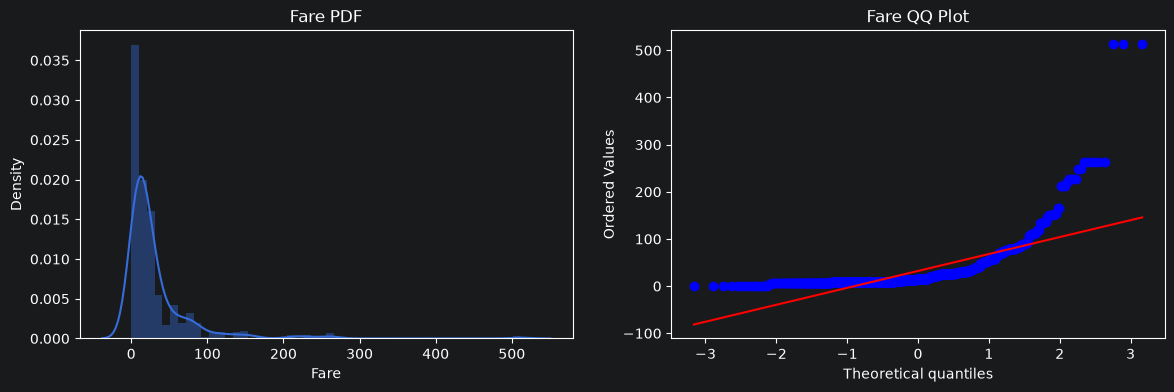

In [110]:
# Fare
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(df['Fare'])
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(df['Fare'], dist='norm', plot=plt)
plt.title("Fare QQ Plot")

As we can observe above figures in that Fare feature is right side skewed so better approach is to apply logarithmic transformer

#### **Before applying Functional Transformer**

In [111]:
clf1 = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [112]:
from sklearn.metrics import accuracy_score

clf1.fit(x_train, y_train)
clf2.fit(x_train, y_train)

y_pred = clf1.predict(x_test)
y_pred1 = clf2.predict(x_test)

print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6536312849162011


#### **After applying Function transformer**

In [113]:
trf = FunctionTransformer(func=np.log1p)

In [114]:
x_train_transformed = trf.fit_transform(x_train)
x_test_transformed = trf.transform(x_test)

In [115]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

clf.fit(x_train_transformed, y_train)
clf1.fit(x_train_transformed, y_train)

y_pred = clf.predict(x_test_transformed)
y_pred1 = clf1.predict(x_test_transformed)

In [116]:
print("Accuracy LR", accuracy_score(y_test, y_pred))
print("Accuracy DT", accuracy_score(y_test, y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6703910614525139


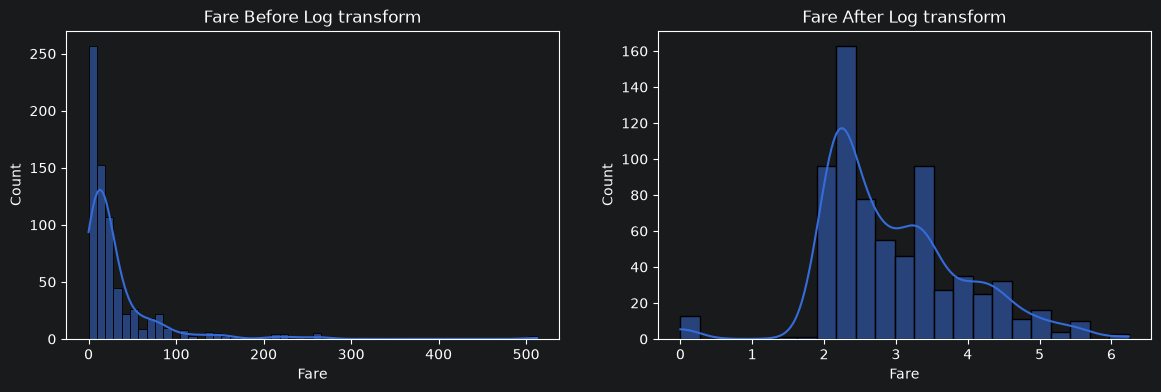

In [127]:
# distribution after transformation
plt.figure(figsize=(14,4))
plt.subplot(121)
# stats.probplot(x_train['Fare'], dist='norm', plot=plt)
sns.histplot(x_train['Fare'], kde=True)
plt.title('Fare Before Log transform')

plt.subplot(122)
# stats.probplot(x_train_transformed['Fare'], dist='norm', plot=plt)
sns.histplot(x_train_transformed['Fare'], kde=True)
plt.title('Fare After Log transform')

plt.show()

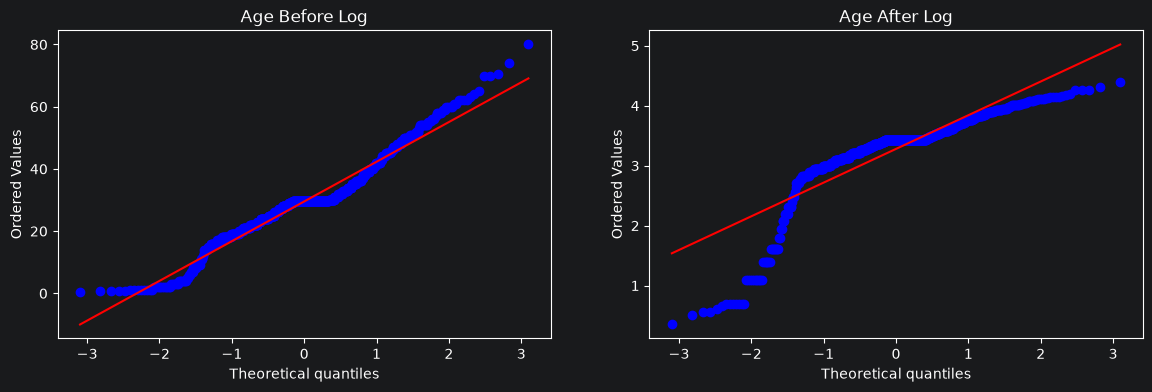

In [129]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(x_train['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(x_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')

plt.show()

In [130]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')

X_train_transformed2 = trf2.fit_transform(x_train)
X_test_transformed2 = trf2.transform(x_test)

In [131]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2,y_train)
clf2.fit(X_train_transformed2,y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.659217877094972


In [133]:
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]

    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')

    X_trans = trf.fit_transform(X)

    clf = LogisticRegression()

    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()

Accuracy 0.6611485642946316


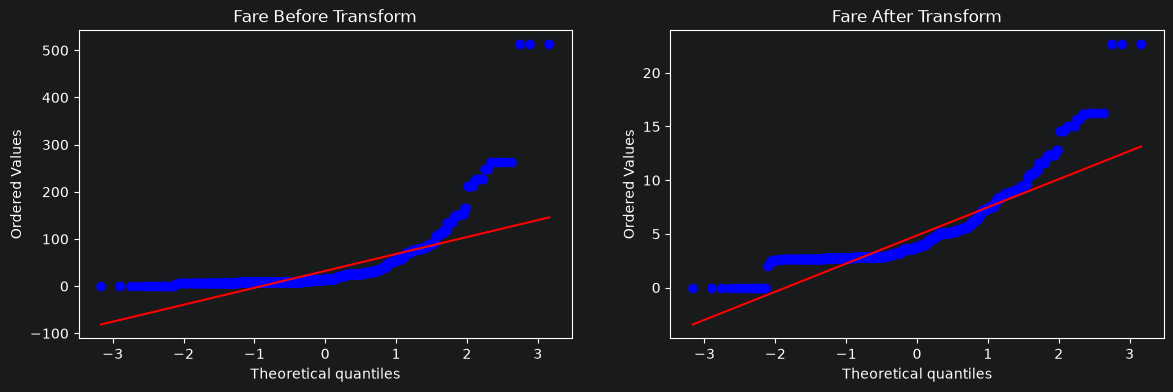

In [141]:
apply_transform(lambda x : x**(1/2))